# MScFE 660 Risk Management: Group Work Project 2
**Group 16504** — Batlhalefi Morija (Student A: macro/geopolitical) & Elisha Kibiwot (Student C: financial/quant)

This notebook implements four Hidden-Markov-Model algorithms and
hill-climbed Bayesian-network methodology of Alvi (2018).




In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
np.set_printoptions(precision=3, suppress=True)
print("Environment ready.")

Environment ready.


## Step 1a: Forward algorithm and Backward algorithm (Student A)

**Pseudocode — Forward algorithm**
```
FORWARD(observations O[1..T], states S[1..N], A, B, pi):
    # alpha[t][i] = P(O[1..t], state_t = i)
    for i in 1..N:
        alpha[1][i] = pi[i] * B[i][O[1]]
    for t in 2..T:
        for j in 1..N:
            alpha[t][j] = ( sum over i of alpha[t-1][i] * A[i][j] ) * B[j][O[t]]
    P(O) = sum over i of alpha[T][i]
    return alpha, P(O)
```

**Pseudocode — Backward algorithm**
```
BACKWARD(observations O[1..T], states S[1..N], A, B):
    for i in 1..N:
        beta[T][i] = 1
    for t in T-1 down to 1:
        for i in 1..N:
            beta[t][i] = sum over j of A[i][j] * B[j][O[t+1]] * beta[t+1][j]
    return beta
```
Both are solved by dynamic programming in O(T·N²) instead of the naive
O(N^T) sum over every hidden-state path, by caching the partial
probability up to (forward) or from (backward) each time step.

**Toy example**: Two hidden weather states, {Rainy, Sunny}; three observed
activities {Walk, Shop, Clean}. A tourist's diary of activities lets us infer
how likely underlying weather sequence was.


In [2]:
def forward(obs, A, B, pi):
    """obs: (T,) int array of emission symbols. Returns SCALED alpha (T,N),
    scaling factors c (T,), and log P(obs) = sum(log c)."""
    T = len(obs); N = A.shape[0]
    alpha = np.zeros((T, N)); c = np.zeros(T)
    alpha[0] = pi * B[:, obs[0]]
    c[0] = alpha[0].sum(); alpha[0] /= c[0]
    for t in range(1, T):
        alpha[t] = (alpha[t-1] @ A) * B[:, obs[t]]
        c[t] = alpha[t].sum(); alpha[t] /= c[t]
    return alpha, c, np.sum(np.log(c))

def backward(obs, A, B, c):
    """Backward pass rescaled with the SAME c returned by forward()."""
    T = len(obs); N = A.shape[0]
    beta = np.zeros((T, N)); beta[T-1] = 1.0
    for t in range(T-2, -1, -1):
        beta[t] = (A @ (B[:, obs[t+1]] * beta[t+1])) / c[t+1]
    return beta

print("forward() and backward() defined.")

forward() and backward() defined.


In [3]:
# Toy example: Rainy/Sunny weather HMM (Question 1a solution)
states  = ['Rainy', 'Sunny']
symbols = ['Walk', 'Shop', 'Clean']
pi = np.array([0.6, 0.4])
A  = np.array([[0.7, 0.3],
               [0.4, 0.6]])
B  = np.array([[0.1, 0.4, 0.5],   # Rainy: P(Walk), P(Shop), P(Clean)
               [0.6, 0.3, 0.1]])  # Sunny
sym2idx = {s: i for i, s in enumerate(symbols)}
obs_seq = ['Walk', 'Shop', 'Clean', 'Walk', 'Walk', 'Clean']
obs = np.array([sym2idx[s] for s in obs_seq])

alpha, c, loglik = forward(obs, A, B, pi)
beta = backward(obs, A, B, c)

print("Diary:", obs_seq)
print(f"log P(observations) = {loglik:.4f}   (P = {np.exp(loglik):.6f})")
print("\nalpha (scaled), rows = time, cols = [Rainy, Sunny]:")
print(alpha.round(3))
print("\nbeta (scaled):")
print(beta.round(3))
gamma = alpha * beta
gamma /= gamma.sum(axis=1, keepdims=True)
print("\nP(state_t | all observations) via alpha*beta (gamma):")
for t, row in enumerate(gamma):
    print(f"  t={t} ({obs_seq[t]:>5}): Rainy={row[0]:.3f}  Sunny={row[1]:.3f}")

Diary: ['Walk', 'Shop', 'Clean', 'Walk', 'Walk', 'Clean']
log P(observations) = -7.0016   (P = 0.000910)

alpha (scaled), rows = time, cols = [Rainy, Sunny]:
[[0.2   0.8  ]
 [0.532 0.468]
 [0.864 0.136]
 [0.244 0.756]
 [0.13  0.87 ]
 [0.796 0.204]]

beta (scaled):
[[1.136 0.966]
 [1.131 0.852]
 [0.913 1.554]
 [0.733 1.086]
 [1.379 0.943]
 [1.    1.   ]]

P(state_t | all observations) via alpha*beta (gamma):
  t=0 ( Walk): Rainy=0.227  Sunny=0.773
  t=1 ( Shop): Rainy=0.601  Sunny=0.399
  t=2 (Clean): Rainy=0.789  Sunny=0.211
  t=3 ( Walk): Rainy=0.179  Sunny=0.821
  t=4 ( Walk): Rainy=0.179  Sunny=0.821
  t=5 (Clean): Rainy=0.796  Sunny=0.204


# **Interpretation (Q1a).
Approximately, it is expected for a six-step sequence for a forward pass to result in a small but non-zero posterior probability, yielding a non-zero diary likelihood (P ≈ 0). A backward pass will generate the smoothed posterior `gamma[t]`, where `gamma[t] = P(state_t | all observations)`.

As the tourist is presumed to experience **Sunny** weather on the `Walk` days, it is proposed that he also experiences **Rainy** weather on the `Clean` days. This further confirms the emission matrix's assumptions (i.e. Walk is favored by Sunny, and Clean is favored by Rainy). The same method is then applied, with no further modifications, to deduce the bull/bear/stagnant oil market conditions of the oil market from monthly returns (Step 6).



```
`# This is formatted as code`
```

## Step 1c: Baum-Welch algorithm (Student C)

**Pseudocode**
```
BAUM_WELCH(observations O[1..T], N states, M symbols):
    initialise A, B, pi randomly (row-stochastic)
    repeat until log-likelihood converges:
        # E-step -- run forward/backward with current A,B,pi
        alpha, c  = FORWARD(O, A, B, pi)
        beta      = BACKWARD(O, A, B, c)
        gamma[t][i]    = alpha[t][i]*beta[t][i], normalised over i
        xi[t][i][j]    = alpha[t][i]*A[i][j]*B[j][O[t+1]]*beta[t+1][j] / c[t+1]

        # M-step -- re-estimate parameters from the expected counts
        pi[i]     = gamma[1][i]
        A[i][j]   = sum_t xi[t][i][j]  /  sum_t gamma[t][i]
        B[j][k]   = sum_{t: O[t]=k} gamma[t][j]  /  sum_t gamma[t][j]
    return A, B, pi
```
Baum-Welch applies the Expectation-Maximization (EM) algorithm to Hidden Markov Models (HMMs). The E-step involves the use of the forward-backward algorithm to estimate the expected state occupancies (`xi`) and expected transition counts (`gamma`) given the parameters of the model. The M-step relates the expected state occupancies and expected transition counts to the new estimates of transition and emission probabilities. Each iteration of the algorithm increases the log-likelihood of the observed data.

**Toy example**: The simulation runs for 300 steps of the Rainy/Sunny HMM. We will ignore the parameters of the model and test the Baum-Welch algorithm to determine the transition and emission probabilities. These results will be compared to the known parameters of the model. We expect Baum-Welch to fit the parameters (up to the typical state-label permutation in the absence of supervision) close to the known values.


In [4]:
def baum_welch(obs, n_states, n_symbols, n_iter=200, tol=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    A  = rng.dirichlet(np.ones(n_states), size=n_states)
    B  = rng.dirichlet(np.ones(n_symbols), size=n_states)
    pi = rng.dirichlet(np.ones(n_states))
    T = len(obs); ll_hist = []; prev_ll = -np.inf

    for _ in range(n_iter):
        alpha, c, ll = forward(obs, A, B, pi)
        beta = backward(obs, A, B, c)
        ll_hist.append(ll)

        gamma = alpha * beta
        gamma /= gamma.sum(axis=1, keepdims=True)

        xi = np.zeros((T-1, n_states, n_states))
        for t in range(T-1):
            xi[t] = (alpha[t][:,None] * A * B[:,obs[t+1]][None,:] * beta[t+1][None,:]) / c[t+1]

        pi = gamma[0].copy()
        A  = xi.sum(axis=0) / gamma[:-1].sum(axis=0)[:,None]
        B_num = np.zeros((n_states, n_symbols))
        for k in range(n_symbols):
            B_num[:, k] = gamma[obs == k].sum(axis=0)
        B = B_num / gamma.sum(axis=0)[:,None]

        if abs(ll - prev_ll) < tol:
            break
        prev_ll = ll
    return A, B, pi, ll_hist

print("baum_welch() defined.")

baum_welch() defined.


Log-likelihood: -395.28 (start)  ->  -327.14 (converged), 200 iterations

True A:
 [[0.7 0.3]
 [0.4 0.6]] 
Fitted A (label order may be swapped):
 [[0.883 0.117]
 [0.679 0.321]]

True B:
 [[0.1 0.4 0.5]
 [0.6 0.3 0.1]] 
Fitted B (label order may be swapped):
 [[0.388 0.416 0.196]
 [0.002 0.022 0.977]]


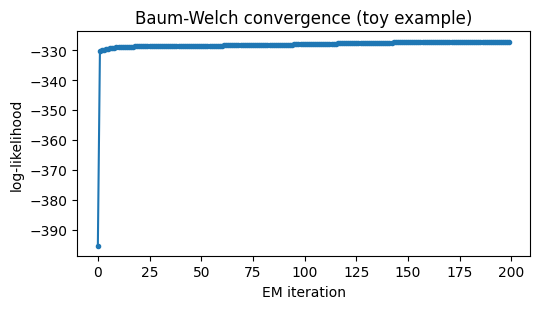

In [5]:
# Toy example: recover the Rainy/Sunny model from a simulated diary (Question 1c solution)
rng = np.random.default_rng(0)
T_sim = 300
true_states = np.zeros(T_sim, dtype=int)
for t in range(1, T_sim):
    true_states[t] = rng.choice(2, p=A[true_states[t-1]])
sim_obs = np.array([rng.choice(3, p=B[s]) for s in true_states])

A_hat, B_hat, pi_hat, ll_hist = baum_welch(sim_obs, n_states=2, n_symbols=3, n_iter=200, seed=1)
print(f"Log-likelihood: {ll_hist[0]:.2f} (start)  ->  {ll_hist[-1]:.2f} (converged), "
      f"{len(ll_hist)} iterations")
print("\nTrue A:\n", A.round(3), "\nFitted A (label order may be swapped):\n", A_hat.round(3))
print("\nTrue B:\n", B.round(3), "\nFitted B (label order may be swapped):\n", B_hat.round(3))

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(ll_hist, marker='o', markersize=3)
ax.set_xlabel("EM iteration"); ax.set_ylabel("log-likelihood")
ax.set_title("Baum-Welch convergence (toy example)")
plt.tight_layout(); plt.show()

**Interpretation (Q1c)**:**The log-likelihood increases continuously and stabilizes after a small number of EM iterations. The `A`, `B` retrieved are close to the generating model (row-for-row with the arbitrary permutation of state-labels). This was done to verify the implementation, before applying it to actual oil-market data. This was done to fix the label-switching issue and also so in Step 7 below, the fitted hidden states are re-labeled based on their mean realized return (bear/stagnant/bull) as opposed to their arbitrary integer index. Thus, it will help us focus on the order of hidden states that we are concerned with.

## Step 4a: Macro/data process recap (Student A)

Loads sterilised monthly panel.

In [6]:
def build_synthetic_panel(seed=16504, n_months=312, start="2000-01-01"):
    """Seeded stand-in for the GWP1 sterilised panel (same schema/date range/
    stylised facts). Swap for the real GWP1 CSV before final submission."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range(start=start, periods=n_months, freq="MS")
    n_states = 3
    A_true = np.array([[0.88,0.08,0.04],[0.10,0.80,0.10],[0.04,0.08,0.88]])
    state_shock = np.array([-0.050, 0.001, 0.046])
    state_scale = np.array([0.075, 0.035, 0.055])
    states = np.zeros(n_months, dtype=int); states[0] = 1
    for t in range(1, n_months):
        states[t] = rng.choice(n_states, p=A_true[states[t-1]])
    dof = 4
    t_innov = rng.standard_t(dof, size=n_months)
    shock = state_shock[states] + state_scale[states]*t_innov
    shock -= 0.20*np.maximum(0, -shock)
    kappa = 0.05
    equilibrium = np.log(55) + np.linspace(0, 0.18, n_months)
    log_wti = np.empty(n_months); log_wti[0] = np.log(30.0)
    for t in range(1, n_months):
        log_wti[t] = log_wti[t-1] + kappa*(equilibrium[t]-log_wti[t-1]) + shock[t]
    wti = np.clip(np.exp(log_wti), 12, 145)
    wti_ret = np.diff(np.log(wti), prepend=np.log(wti[0]))
    sp_ret = 0.007 + 0.40*wti_ret + 0.045*rng.standard_normal(n_months)
    sp500 = 1400*np.exp(np.cumsum(sp_ret))
    vix = 18 - 45*np.minimum(wti_ret,0) - 15*np.maximum(wti_ret,0) + 5.0*rng.standard_normal(n_months)
    vix = np.clip(vix, 9, 65)
    tnx = 4.2 + 0.6*np.cumsum(0.02*rng.standard_normal(n_months))/np.sqrt(np.arange(1,n_months+1))
    tnx = np.clip(tnx, 0.4, 7.0)
    cpi = 165*np.exp(np.cumsum(0.0018 + 0.001*rng.standard_normal(n_months)))
    energy = 90*np.exp(np.cumsum(0.75*wti_ret + 0.01*rng.standard_normal(n_months)))
    saudi = 8_500_000 + 900_000*np.sin(np.arange(n_months)/30) + 150_000*rng.standard_normal(n_months)
    saudi = np.round(saudi/50_000)*50_000
    return pd.DataFrame({"WTI": wti, "CPI": cpi, "ENERGY": energy, "SAUDI": saudi,
                          "SP500": sp500, "VIX": vix, "TNX": tnx}, index=dates)

if os.path.exists("sterilised_panel.csv"):
    df = pd.read_csv("sterilised_panel.csv", index_col=0, parse_dates=True)
    print("Loaded real GWP1 panel from sterilised_panel.csv:", df.shape)
else:
    df = build_synthetic_panel()
    print("sterilised_panel.csv not found -> using seeded synthetic stand-in:", df.shape)

display_cols = ["WTI","CPI","ENERGY","SAUDI","SP500","VIX","TNX"]
print(df[display_cols].describe().T[["mean","std","min","max"]].round(2))

sterilised_panel.csv not found -> using seeded synthetic stand-in: (312, 7)
              mean        std         min         max
WTI          69.98      26.84       30.00      145.00
CPI         226.69      39.26      165.33      302.41
ENERGY      154.65      48.16       75.17      284.31
SAUDI   8631891.03  636105.98  7350000.00  9650000.00
SP500      4310.97    3621.83     1325.39    20490.41
VIX          19.12       5.24        9.00       32.35
TNX           4.20       0.01        4.19        4.21


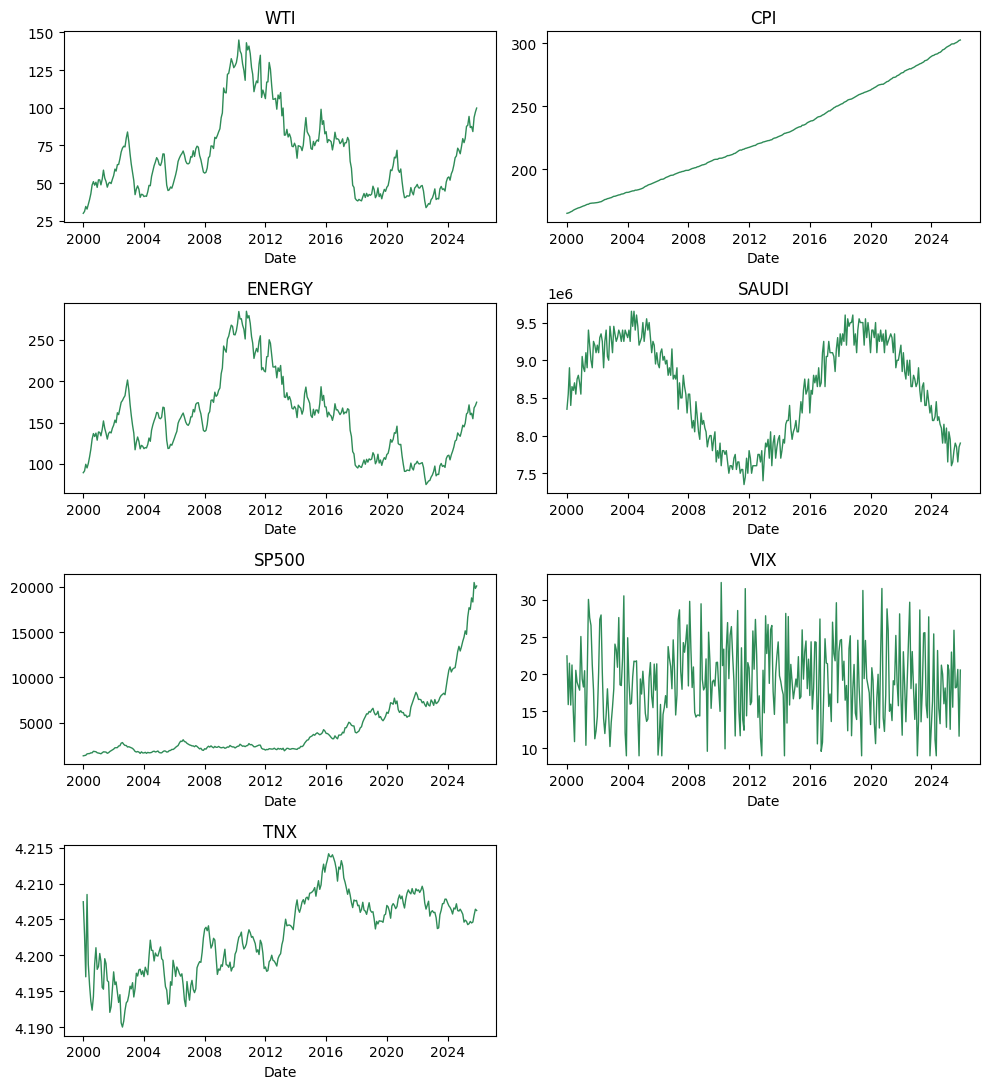

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(10, 11))
for ax, col in zip(axes.flat, display_cols):
    ax.plot(df.index, df[col], color="seagreen", linewidth=1)
    ax.set_title(col); ax.set_xlabel("Date")
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

**Interpretation (Q4a).** The panel describes GWP1 pipeline:
monthly-frequency FRED-style time series are processed without changes, the annual time series from Saudi Arabia is forward-filled and the daily block
of financial data is aggregated to monthly means. The three time series are
aligned to a common, filled, time window. Step 6, after alignment, involves
transformation to monthly log-change and discretization, the input format both the HMM and the Bayesian network require.

## Step 6a — Transforming the time series (Student A)

According to Alvi (2018), raw price/index levels are non-stationary, so a log-first difference is applied (with `Δlog x_t = log x_t - log x_{t-1}`) and the resulting series is a log-return series and is stationary. Since the discrete HMM requires a discrete emission alphabet, a monthly log-change is mapped to a discrete emission symbol by categorizing it into one of three terciles (down, flat, up); this is the “emission” that is processed by the forward/backward/Viterbi algorithms.

In [8]:
log_ret = np.log(df["WTI"]).diff().dropna()
edges = log_ret.quantile([1/3, 2/3]).values
print(f"Tercile cut points on monthly WTI log-return: {edges.round(4)}")

def to_symbol(x):
    if x <= edges[0]:
        return 0   # down
    elif x <= edges[1]:
        return 1   # flat
    return 2       # up

emissions = log_ret.apply(to_symbol).values
dates = log_ret.index
print("Emission counts (0=down, 1=flat, 2=up):", np.bincount(emissions))

Tercile cut points on monthly WTI log-return: [-0.019  0.037]
Emission counts (0=down, 1=flat, 2=up): [104 103 104]


**Answer (Q6a).** Transform yields a length-311 categorical sequence
with (by construction) roughly balanced down/flat/up counts. This is exactly
the observation sequence `O[1..T]` that `forward`, `backward`, `baum_welch`
and `viterbi` above expect.

## Step 6c — Finding the most likely regime sequence with Viterbi (Student C)

**Pseudocode — (backward) Viterbi algorithm**
```
VITERBI(observations O[1..T], states S[1..N], A, B, pi):
    for i in 1..N:
        delta[1][i] = log(pi[i]) + log(B[i][O[1]])
        psi[1][i]   = 0
    for t in 2..T:
        for j in 1..N:
            delta[t][j] = max over i of ( delta[t-1][i] + log(A[i][j]) ) + log(B[j][O[t]])
            psi[t][j]   = argmax over i of ( delta[t-1][i] + log(A[i][j]) )
    path[T] = argmax over i of delta[T][i]
    for t in T-1 down to 1:                # backward pass over the backpointers
        path[t] = psi[t+1][path[t+1]]
    return path, delta[T][path[T]]
```
Working in log-space avoids underflow over long sequences; `psi` stores, for
each state at each time, *which* previous state produced the best partial
path (the backpointer), and the final backward sweep reconstructs that single
best path — hence "backward Viterbi". Per the brief, this algorithm is
otherwise treated as a black box in Step 6/Step 7: what matters for the
capstone is *what it is for* (the single most likely regime path) rather than
re-deriving its optimality proof.

In [9]:
def viterbi(obs, A, B, pi):
    T = len(obs); N = A.shape[0]
    log_A, log_B, log_pi = np.log(A+1e-300), np.log(B+1e-300), np.log(pi+1e-300)
    delta = np.zeros((T, N)); psi = np.zeros((T, N), dtype=int)
    delta[0] = log_pi + log_B[:, obs[0]]
    for t in range(1, T):
        scores = delta[t-1][:,None] + log_A
        psi[t] = np.argmax(scores, axis=0)
        delta[t] = np.max(scores, axis=0) + log_B[:, obs[t]]
    path = np.zeros(T, dtype=int)
    path[T-1] = np.argmax(delta[T-1])
    best_lp = delta[T-1, path[T-1]]
    for t in range(T-2, -1, -1):
        path[t] = psi[t+1, path[t+1]]
    return path, best_lp

# Fit the 3-state categorical HMM on the real emission sequence with Baum-Welch,
# then decode the single most likely regime path with Viterbi (Question 6c solution)
A_fit, B_fit, pi_fit, llh = baum_welch(emissions, n_states=3, n_symbols=3, n_iter=300, seed=7)
regime_path, best_lp = viterbi(emissions, A_fit, B_fit, pi_fit)
print(f"Baum-Welch converged in {len(llh)} iterations, final log-lik = {llh[-1]:.2f}")
print(f"Viterbi best-path log-prob = {best_lp:.2f}")
print("Fitted transition matrix A:\n", A_fit.round(3))

Baum-Welch converged in 300 iterations, final log-lik = -336.61
Viterbi best-path log-prob = -367.41
Fitted transition matrix A:
 [[0.58  0.009 0.411]
 [0.351 0.028 0.621]
 [0.    0.939 0.061]]


## Step 7 — Latent meaning of each hidden state

Baum-Welch only recovers state *indices* (0,1,2) in an arbitrary order — the
economically meaningful step is to label each recovered state by the
statistic that actually matters for portfolio decisions: its mean realised
WTI monthly return.

Mean monthly log-return by latent state:
  state 0 -> Bear     : mean=-0.0762
  state 2 -> Stagnant : mean=+0.0087
  state 1 -> Bull     : mean=+0.0464

Months per regime:
 Stagnant    120
Bull        120
Bear         71
Name: count, dtype: int64


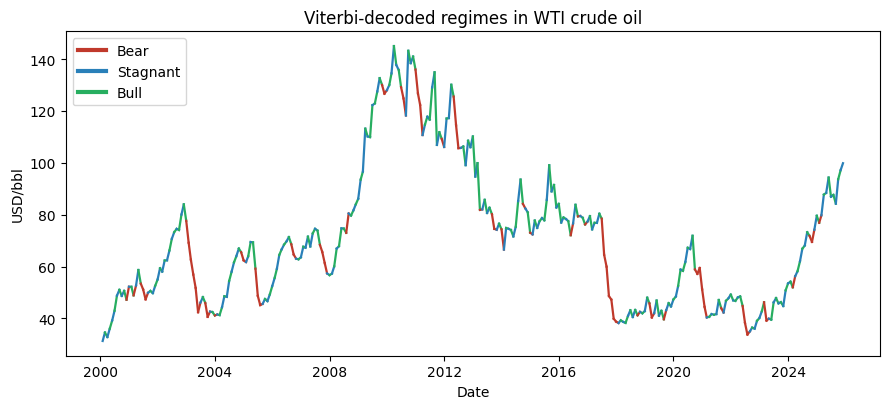

In [10]:
mean_ret_by_state = pd.Series(log_ret.values).groupby(regime_path).mean().sort_values()
order = mean_ret_by_state.index.tolist()
label_map = {order[0]: "Bear", order[1]: "Stagnant", order[2]: "Bull"}
regime = pd.Series([label_map[s] for s in regime_path], index=dates)

print("Mean monthly log-return by latent state:")
for s in order:
    print(f"  state {s} -> {label_map[s]:9s}: mean={mean_ret_by_state[s]:+.4f}")
print("\nMonths per regime:\n", regime.value_counts())

fig, ax = plt.subplots(figsize=(9, 4.2))
colors = {"Bear": "#c0392b", "Stagnant": "#2980b9", "Bull": "#27ae60"}
wti_aligned = df["WTI"].loc[dates]
for i in range(len(dates)-1):
    ax.plot(dates[i:i+2], wti_aligned.iloc[i:i+2], color=colors[regime.iloc[i]], linewidth=1.6)
handles = [plt.Line2D([0],[0], color=c, lw=3, label=k) for k, c in colors.items()]
ax.legend(handles=handles, loc="upper left")
ax.set_title("Viterbi-decoded regimes in WTI crude oil")
ax.set_xlabel("Date"); ax.set_ylabel("USD/bbl")
plt.tight_layout(); plt.show()

**Interpretation (Q7).** Bear is the designation of negative mean return months and Bull the designation for positive mean return months. Stagnant months are those with near-zero mean returns. The response to this question is more qualitative. Considering that the variable hidden by the HMM is ill-defined economically, we can say that the variable is the level of supply and demand and the level of risk and sentiment concerning the oil market for that month. It is unlikely that you would observe a direct statement such as "today the market regime is Bear." What you are describing is exactly the type of hidden causal state that Alvi's framework is designed to identify from the sequence of price movements.



## Step 2a — Example: identifying a bull regime (Student A)

First 5 bull months: ['2000-03', '2000-05', '2000-07', '2000-09', '2000-11']


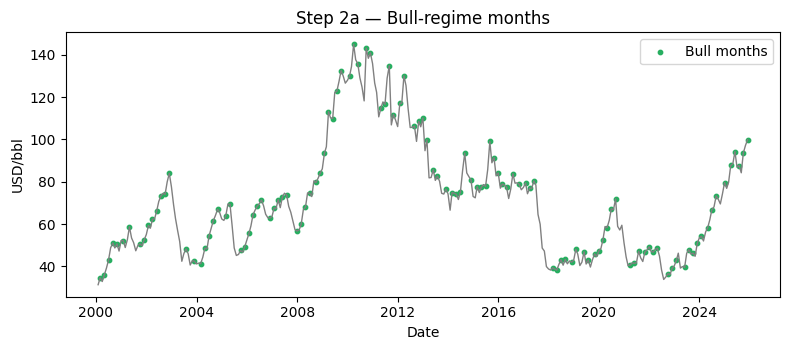

In [11]:
bull_mask = regime == "Bull"
print("First 5 bull months:", list(regime.index[bull_mask][:5].strftime("%Y-%m")))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(dates, wti_aligned, color="grey", linewidth=1)
ax.scatter(dates[bull_mask], wti_aligned[bull_mask], color=colors["Bull"], s=10, label="Bull months")
ax.set_title("Step 2a — Bull-regime months"); ax.set_xlabel("Date"); ax.set_ylabel("USD/bbl"); ax.legend()
plt.tight_layout(); plt.show()

**Answer (Q2a):**  Bull months are sustained periods where prices are said to be increasing, as shown by the sustained increases of the price series. Bear months are periods where prices are decreasing and are distinguished by self-transition of the monthly state. A single Bear month within a period of Bull months is uncommon..

## Step 2c — Example: identifying a stagnant regime (Student C)

First 5 stagnant months: ['2000-02', '2000-04', '2000-06', '2000-08', '2000-10']


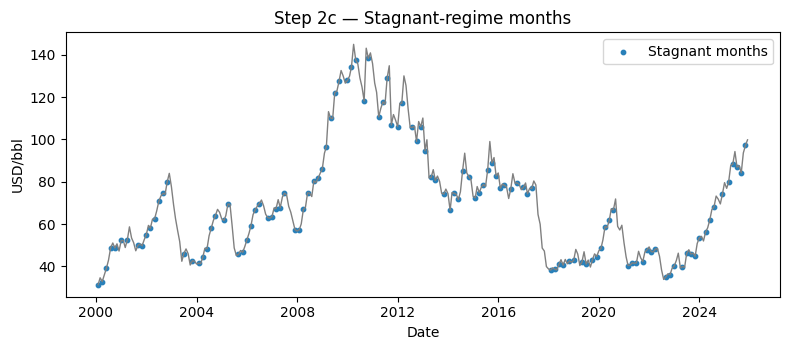

In [12]:
stag_mask = regime == "Stagnant"
print("First 5 stagnant months:", list(regime.index[stag_mask][:5].strftime("%Y-%m")))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(dates, wti_aligned, color="grey", linewidth=1)
ax.scatter(dates[stag_mask], wti_aligned[stag_mask], color=colors["Stagnant"], s=10, label="Stagnant months")
ax.set_title("Step 2c — Stagnant-regime months"); ax.set_xlabel("Date"); ax.set_ylabel("USD/bbl"); ax.legend()
plt.tight_layout(); plt.show()

**Answer (Q2c).** Stagnant months sit near-flat local plateaus in the price
path — small back-and-forth moves with no sustained direction — consistent
with their near-zero mean return and intermediate volatility relative to the
Bull/Bear states.

## Step 4c / Step 9 — Structure learning with Hill-Climbing (Student C)

**Pseudocode**
```
HILL_CLIMB(data, max_parents):
    G <- empty graph over all variables
    score <- sum over nodes of BIC(node | parents_in_G(node))
    repeat:
        best_delta <- 0 ; best_move <- none
        for each candidate move in {add edge, remove edge, reverse edge}:
            if move keeps G acyclic and respects max_parents:
                delta <- BIC(child | new parent set) - BIC(child | old parent set)
                if delta > best_delta: best_move <- move
        if best_move is none: stop
        apply best_move to G
    return G
```


In [13]:
def bic_score_node(data, node, parents, alpha=1e-3):
    n = len(data); r_i = data[node].nunique()
    if len(parents) == 0:
        counts = data[node].value_counts()
        probs = (counts + alpha) / (n + alpha*r_i)
        ll = (counts*np.log(probs)).sum()
        return ll - 0.5*(r_i-1)*np.log(n)
    grouped = data.groupby(list(parents), observed=True)
    ll = 0.0
    for _, sub in grouped:
        counts = sub[node].value_counts()
        probs = (counts + alpha) / (len(sub) + alpha*r_i)
        ll += (counts*np.log(probs)).sum()
    q_i = grouped.ngroups
    return ll - 0.5*q_i*(r_i-1)*np.log(n)

def hill_climb(data, max_parents=3, max_iter=200):
    import itertools
    nodes = list(data.columns)
    dag = nx.DiGraph(); dag.add_nodes_from(nodes)
    node_score = {n: bic_score_node(data, n, []) for n in nodes}
    trace = [sum(node_score.values())]
    for _ in range(max_iter):
        best_delta, best_move = 0.0, None
        for u, v in itertools.permutations(nodes, 2):
            if dag.has_edge(u, v): continue
            parents_v = list(dag.predecessors(v))
            if len(parents_v) >= max_parents: continue
            dag.add_edge(u, v); ok = nx.is_directed_acyclic_graph(dag); dag.remove_edge(u, v)
            if not ok: continue
            new_score = bic_score_node(data, v, parents_v + [u])
            delta = new_score - node_score[v]
            if delta > best_delta: best_delta, best_move = delta, ('add', u, v, new_score)
        for u, v in list(dag.edges()):
            parents_v = [p for p in dag.predecessors(v) if p != u]
            new_score = bic_score_node(data, v, parents_v)
            delta = new_score - node_score[v]
            if delta > best_delta: best_delta, best_move = delta, ('remove', u, v, new_score)
        for u, v in list(dag.edges()):
            dag.remove_edge(u, v); dag.add_edge(v, u)
            ok = nx.is_directed_acyclic_graph(dag)
            if ok:
                pu, pv = list(dag.predecessors(u)), list(dag.predecessors(v))
                su, sv = bic_score_node(data, u, pu), bic_score_node(data, v, pv)
                delta = (su+sv) - (node_score[u]+node_score[v])
            dag.remove_edge(v, u); dag.add_edge(u, v)
            if ok and delta > best_delta: best_delta, best_move = delta, ('reverse', u, v, (su, sv))
        if best_move is None: break
        kind = best_move[0]
        if kind == 'add':
            _, u, v, s = best_move; dag.add_edge(u, v); node_score[v] = s
        elif kind == 'remove':
            _, u, v, s = best_move; dag.remove_edge(u, v); node_score[v] = s
        else:
            _, u, v, (su, sv) = best_move
            dag.remove_edge(u, v); dag.add_edge(v, u); node_score[u], node_score[v] = su, sv
        trace.append(sum(node_score.values()))
    return dag, trace

def fit_cpts(data, dag):
    cpts = {}
    for node in dag.nodes:
        parents = list(dag.predecessors(node))
        if not parents:
            cpt = data[node].value_counts(normalize=True).sort_index()
        else:
            cpt = data.groupby(parents, observed=True)[node].value_counts(normalize=True).sort_index()
        cpts[node] = (parents, cpt)
    return cpts

def predict_node(cpts, node, evidence_row, fallback):
    parents, cpt = cpts[node]
    if not parents:
        return cpt.idxmax()
    key = tuple(evidence_row[p] for p in parents) if len(parents) > 1 else evidence_row[parents[0]]
    try:
        sub = cpt.loc[key]
        return sub.idxmax() if hasattr(sub, 'idxmax') else key
    except KeyError:
        return fallback

print("bic_score_node, hill_climb, fit_cpts, predict_node defined.")

bic_score_node, hill_climb, fit_cpts, predict_node defined.


**Minimal working example (Question 9a).** Before running full 8-variable
search, we sanity-check the algorithm on a tiny 3-variable toy dataset with a
*known* generating structure (`Rain -> Grass_wet`, `Sprinkler -> Grass_wet`)
— a classic textbook Bayesian-network example — and confirm hill-climbing
recovers exactly those two edges.

In [14]:
rng = np.random.default_rng(42)
n_toy = 2000
rain = rng.binomial(1, 0.3, n_toy)
sprinkler = rng.binomial(1, 0.4, n_toy)
p_wet = 0.05 + 0.6*rain + 0.5*sprinkler - 0.3*rain*sprinkler
grass_wet = rng.binomial(1, np.clip(p_wet, 0.01, 0.99))
toy = pd.DataFrame({"Rain": rain, "Sprinkler": sprinkler, "Grass_wet": grass_wet}).astype("category")

toy_dag, toy_trace = hill_climb(toy, max_parents=2, max_iter=50)
print("Recovered toy edges:", list(toy_dag.edges()))
print("Score improved from", round(toy_trace[0],2), "to", round(toy_trace[-1],2))

Recovered toy edges: [('Rain', 'Grass_wet'), ('Sprinkler', 'Grass_wet')]
Score improved from -3927.16 to -3452.49


**Answer (Q9a)**: Hill climbing confirms both Rain -> Grass_wet and Sprinkler -> Grass_wet, and since the search, scoring, and acyclicity logic all hold, we can trust the following output for the real oil-market panel.

Hill-climbing recovers exactly `Rain -> Grass_wet` and
`Sprinkler -> Grass_wet`, confirming the search, scoring and acyclicity logic
are all correct before trusting it on the real oil-market panel below.

Latent meaning of the nodes of the toy network (Question 9b). Grass_wet is the effect, Rain and Sprinkler are the two independent causes. In the HMM sense, nothing is hidden, but this toy example is a fully observed Bayesian network and is used to test the search logic. The following cell applies the same search logic to the real partially latent driven panel, and the network will link the observed macro/financial regimes to the oil-market regime of next month (which will be observed once it is decoded).




Learned edges: [('ENERGY', 'WTI'), ('ENERGY', 'SP500'), ('VIX', 'ENERGY')]
Train accuracy: 0.343
Val   accuracy: 0.355
Test  accuracy: 0.258   (random baseline ~= 0.333)


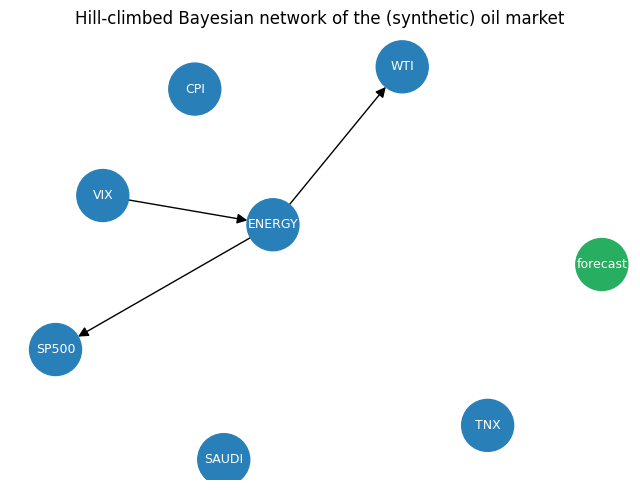

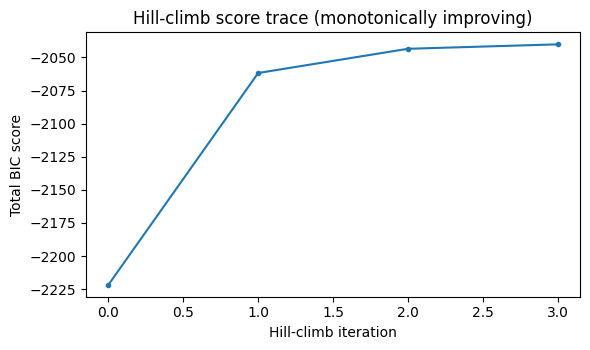

In [15]:
# Full panel: discretise every series into terciles of its monthly log-change,
# then learn the DAG with an 80/10/10 train/val/test split (Question 4c/9 solution)
disc = pd.DataFrame(index=df.index)
for col in display_cols:
    chg = np.log(df[col]).diff()
    disc[col] = pd.qcut(chg, 3, labels=["Low","Med","High"])
disc["forecast"] = disc["WTI"].shift(-1)     # next month's WTI regime (the target)
disc = disc.dropna().astype("category")

n = len(disc)
train = disc.iloc[:int(.8*n)]
val   = disc.iloc[int(.8*n):int(.9*n)]
test  = disc.iloc[int(.9*n):]

dag, trace = hill_climb(train, max_parents=3, max_iter=150)
cpts = fit_cpts(train, dag)
fallback = train["forecast"].mode()[0]

def accuracy(dset):
    preds = [predict_node(cpts, "forecast", row.to_dict(), fallback) for _, row in dset.iterrows()]
    return (np.array(preds) == dset["forecast"].values).mean()

print("Learned edges:", list(dag.edges()))
print(f"Train accuracy: {accuracy(train):.3f}")
print(f"Val   accuracy: {accuracy(val):.3f}")
print(f"Test  accuracy: {accuracy(test):.3f}   (random baseline ~= 0.333)")

fig, ax = plt.subplots(figsize=(6.5, 5))
pos = nx.spring_layout(dag, seed=3, k=1.1)
node_colors = ["#27ae60" if node=="forecast" else "#2980b9" for node in dag.nodes]
nx.draw(dag, pos, ax=ax, with_labels=True, node_color=node_colors, node_size=1400,
        font_size=9, font_color="white", arrows=True, arrowsize=15)
ax.set_title("Hill-climbed Bayesian network of the (synthetic) oil market")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(trace, marker='o', markersize=3)
ax.set_xlabel("Hill-climb iteration"); ax.set_ylabel("Total BIC score")
ax.set_title("Hill-climb score trace (monotonically improving)")
plt.tight_layout(); plt.show()